<a href="https://colab.research.google.com/github/I7411/TH_BIGDATA/blob/main/HuynhThanhMinhTam_2001230789_BT2_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install pyspark

In [2]:
import os, time, shutil, statistics
import pandas as pd
import matplotlib.pyplot as plt
import psutil
from pyspark.sql import SparkSession, functions as F, types as T

spark = (SparkSession.builder
         .master("local[2]")
         .appName("Lab04_Spark_SQL")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.sql.adaptive.enabled", "true")
         .getOrCreate())

print("Spark:", spark.version)
print("CPU cores:", os.cpu_count())
print("RAM (GiB):", round(psutil.virtual_memory().total / 2**30, 2))
print("Master:", spark.sparkContext.master)

Spark: 4.0.5
CPU cores: 2
RAM (GiB): 12.67
Master: local[2]


In [3]:
from google.colab import drive
drive.mount("/content/drive")

NAME = "Lab04_Bai1_US_Retail_Orders.csv"
SOURCE = f"/content/drive/MyDrive/BigData_Lab04/{NAME}"
DATA_PATH = f"/content/{NAME}"

assert os.path.exists(SOURCE), "Place CSV in MyDrive/BigData_Lab04"
shutil.copy2(SOURCE, DATA_PATH)

print("Input file (MiB):", round(os.path.getsize(DATA_PATH) / 2**20, 2))

Mounted at /content/drive
Input file (MiB): 53.78


In [4]:
SALES_SCHEMA = T.StructType([
    T.StructField("order_id", T.StringType()),
    T.StructField("order_date", T.StringType()),
    T.StructField("customer_id", T.LongType()),
    T.StructField("customer_segment", T.StringType()),
    T.StructField("customer_city", T.StringType()),
    T.StructField("customer_state", T.StringType()),
    T.StructField("region", T.StringType()),
    T.StructField("product_id", T.IntegerType()),
    T.StructField("product_category", T.StringType()),
    T.StructField("product_name", T.StringType()),
    T.StructField("brand", T.StringType()),
    T.StructField("unit_price_usd", T.DecimalType(14, 2)),
    T.StructField("quantity", T.IntegerType()),
    T.StructField("discount_rate", T.DecimalType(4, 2)),
    T.StructField("gross_amount_usd", T.DecimalType(16, 2)),
    T.StructField("discount_amount_usd", T.DecimalType(16, 2)),
    T.StructField("net_amount_usd", T.DecimalType(16, 2)),
    T.StructField("sales_channel", T.StringType()),
    T.StructField("warehouse_id", T.StringType()),
    T.StructField("warehouse_state", T.StringType()),
    T.StructField("payment_method", T.StringType()),
    T.StructField("member_tier", T.StringType()),
    T.StructField("promo_banner_color", T.StringType()),
    T.StructField("receipt_template", T.StringType()),
    T.StructField("internal_audit_code", T.StringType())
])

raw = (spark.read.option("header", "true")
       .schema(SALES_SCHEMA).csv(DATA_PATH))

orders = (raw.withColumn("order_date", F.to_date("order_date"))
          .withColumn("order_year", F.year("order_date"))
          .withColumn("order_month", F.month("order_date")))

print("Rows:", orders.count(), "Original Columns:", len(raw.columns), "Total Columns after derived:", len(orders.columns))
orders.printSchema()
orders.select("order_id", "customer_id", "product_id", "net_amount_usd", "order_year", "order_month").show(5, truncate=False)

Rows: 300000 Original Columns: 25 Total Columns after derived: 27
root
 |-- order_id: string (nullable = true)
 |-- order_date: date (nullable = true)
 |-- customer_id: long (nullable = true)
 |-- customer_segment: string (nullable = true)
 |-- customer_city: string (nullable = true)
 |-- customer_state: string (nullable = true)
 |-- region: string (nullable = true)
 |-- product_id: integer (nullable = true)
 |-- product_category: string (nullable = true)
 |-- product_name: string (nullable = true)
 |-- brand: string (nullable = true)
 |-- unit_price_usd: decimal(14,2) (nullable = true)
 |-- quantity: integer (nullable = true)
 |-- discount_rate: decimal(4,2) (nullable = true)
 |-- gross_amount_usd: decimal(16,2) (nullable = true)
 |-- discount_amount_usd: decimal(16,2) (nullable = true)
 |-- net_amount_usd: decimal(16,2) (nullable = true)
 |-- sales_channel: string (nullable = true)
 |-- warehouse_id: string (nullable = true)
 |-- warehouse_state: string (nullable = true)
 |-- payment

In [5]:
CUSTOMER_COLS = ["customer_id", "customer_segment", "customer_city",
                 "customer_state", "region", "member_tier"]
PRODUCT_COLS = ["product_id", "product_category", "product_name", "brand"]
WAREHOUSE_COLS = ["warehouse_id", "warehouse_state"]

for key, attrs in [("customer_id", CUSTOMER_COLS),
                   ("product_id", PRODUCT_COLS),
                   ("warehouse_id", WAREHOUSE_COLS)]:
    profiles = orders.select(*attrs).distinct().count()
    keys = orders.select(key).distinct().count()
    print(key, "keys:", keys, "profiles:", profiles)
    assert profiles == keys, f"Conflicting attributes for {key}"

fact = orders.select(
    "order_id", "order_date", "order_year", "order_month",
    "customer_id", "product_id", "warehouse_id",
    "quantity", "unit_price_usd", "discount_rate",
    "gross_amount_usd", "discount_amount_usd", "net_amount_usd",
    "sales_channel"
)

frames = {
    "f_orders": fact,
    "d_customers": orders.select(*CUSTOMER_COLS).distinct(),
    "d_products": orders.select(*PRODUCT_COLS).distinct(),
    "d_warehouses": orders.select(*WAREHOUSE_COLS).distinct()
}

STAGE = "/content/lab04_sql_tables"
for name, frame in frames.items():
    path = f"{STAGE}/{name}"
    frame.write.mode("overwrite").parquet(path)
    spark.read.parquet(path).createOrReplaceTempView(name)
    print(name, spark.table(name).count())

customer_id keys: 14400 profiles: 14400
product_id keys: 240 profiles: 240
warehouse_id keys: 16 profiles: 16
f_orders 300000
d_customers 14400
d_products 240
d_warehouses 16


In [6]:
joined_rows = spark.sql("""
SELECT COUNT(*) AS n
FROM f_orders o
JOIN d_customers c ON o.customer_id = c.customer_id
JOIN d_products p ON o.product_id = p.product_id
JOIN d_warehouses w ON o.warehouse_id = w.warehouse_id
""").first()["n"]

assert joined_rows == spark.table("f_orders").count()
print("Rows after joins:", joined_rows)

Rows after joins: 300000


In [7]:
q_channel = """
SELECT sales_channel,
       COUNT(*) AS transactions,
       COUNT(DISTINCT customer_id) AS unique_customers,
       SUM(quantity) AS units,
       ROUND(SUM(net_amount_usd), 2) AS revenue_usd
FROM f_orders
WHERE order_year = 2025
GROUP BY sales_channel
HAVING COUNT(*) >= 100
ORDER BY revenue_usd DESC
"""
spark.sql(q_channel).show(truncate=False)

q_region = """
SELECT c.region, p.product_category,
       COUNT(*) AS transactions,
       COUNT(DISTINCT o.customer_id) AS unique_customers,
       ROUND(SUM(o.net_amount_usd), 2) AS revenue_usd
FROM f_orders o
JOIN d_customers c ON o.customer_id = c.customer_id
JOIN d_products p ON o.product_id = p.product_id
GROUP BY c.region, p.product_category
ORDER BY revenue_usd DESC
"""
spark.sql(q_region).show(15, truncate=False)

+-------------+------------+----------------+------+-----------+
|sales_channel|transactions|unique_customers|units |revenue_usd|
+-------------+------------+----------------+------+-----------+
|Online       |67787       |14400           |271096|23015576.69|
|Store        |67791       |14400           |271116|22978807.86|
|Marketplace  |64967       |14400           |259846|21997050.80|
+-------------+------------+----------------+------+-----------+

+-------+----------------+------------+----------------+-----------+
|region |product_category|transactions|unique_customers|revenue_usd|
+-------+----------------+------------+----------------+-----------+
|South  |Apparel         |18314       |4800            |6208226.22 |
|South  |Office          |18345       |4800            |5776391.03 |
|West   |Apparel         |16124       |4246            |5475038.26 |
|South  |Electronics     |18345       |4800            |5461110.48 |
|West   |Office          |16116       |4246            |50831

In [8]:
q_top5 = """
WITH product_totals AS (
    SELECT c.region, p.product_id, p.product_name,
           COUNT(*) AS transactions,
           SUM(o.net_amount_usd) AS revenue_usd
    FROM f_orders o
    JOIN d_customers c ON o.customer_id = c.customer_id
    JOIN d_products p ON o.product_id = p.product_id
    GROUP BY c.region, p.product_id, p.product_name
), ranked AS (
    SELECT *,
           ROW_NUMBER() OVER (
               PARTITION BY region
               ORDER BY revenue_usd DESC, product_id ASC
           ) AS product_rank
    FROM product_totals
)
SELECT region, product_id, product_name, transactions,
       ROUND(revenue_usd, 2) AS revenue_usd, product_rank
FROM ranked
WHERE product_rank <= 5
ORDER BY region, product_rank
"""
spark.sql(q_top5).show(30, truncate=False)

+-------+----------+-----------------------+------------+-----------+------------+
|region |product_id|product_name           |transactions|revenue_usd|product_rank|
+-------+----------+-----------------------+------------+-----------+------------+
|East   |31195     |Apparel Product 195    |370         |222503.87  |1           |
|East   |31190     |Office Product 190     |369         |212419.10  |2           |
|East   |31185     |Electronics Product 185|367         |206321.13  |3           |
|East   |31030     |Office Product 030     |370         |203679.36  |4           |
|East   |31035     |Apparel Product 035    |362         |203257.62  |5           |
|Midwest|31195     |Apparel Product 195    |308         |179865.77  |1           |
|Midwest|31190     |Office Product 190     |304         |175812.05  |2           |
|Midwest|31099     |Apparel Product 099    |302         |169733.81  |3           |
|Midwest|31185     |Electronics Product 185|302         |168307.71  |4           |
|Mid

In [9]:
q_filter = spark.sql("""
SELECT order_id, customer_id, net_amount_usd
FROM f_orders
WHERE order_year = 2025 AND sales_channel = 'Online'
LIMIT 10
""")
print("PLAN: simple filter")
q_filter.explain(mode="formatted")

print("PLAN: join and aggregate")
spark.sql(q_region).explain(mode="formatted")

PLAN: simple filter
== Physical Plan ==
CollectLimit (5)
+- * Project (4)
   +- * Filter (3)
      +- * ColumnarToRow (2)
         +- Scan parquet  (1)


(1) Scan parquet 
Output [5]: [order_id#150, order_year#152, customer_id#154L, net_amount_usd#162, sales_channel#163]
Batched: true
Location: InMemoryFileIndex [file:/content/lab04_sql_tables/f_orders]
PushedFilters: [IsNotNull(order_year), IsNotNull(sales_channel), EqualTo(order_year,2025), EqualTo(sales_channel,Online)]
ReadSchema: struct<order_id:string,order_year:int,customer_id:bigint,net_amount_usd:decimal(16,2),sales_channel:string>

(2) ColumnarToRow [codegen id : 1]
Input [5]: [order_id#150, order_year#152, customer_id#154L, net_amount_usd#162, sales_channel#163]

(3) Filter [codegen id : 1]
Input [5]: [order_id#150, order_year#152, customer_id#154L, net_amount_usd#162, sales_channel#163]
Condition : (((isnotnull(order_year#152) AND isnotnull(sales_channel#163)) AND (order_year#152 = 2025)) AND (sales_channel#163 = Online))



In [10]:
def benchmark_sql(query, repeats=3):
    spark.sql(query).collect() # warm up (small aggregate only)
    values = []
    last_rows = None
    for _ in range(repeats):
        t0 = time.perf_counter()
        last_rows = spark.sql(query).collect()
        values.append(time.perf_counter() - t0)
    return statistics.median(values), last_rows

JOIN_BASE = """
SELECT c.region, p.product_category,
       ROUND(SUM(o.net_amount_usd), 2) AS revenue_usd
FROM f_orders o
JOIN d_customers c ON o.customer_id = c.customer_id
JOIN d_products p ON o.product_id = p.product_id
GROUP BY c.region, p.product_category
ORDER BY c.region, p.product_category
"""

JOIN_HINT = JOIN_BASE.replace(
    "SELECT c.region", "SELECT /*+ BROADCAST(p, c) */ c.region", 1)

old_aqe = spark.conf.get("spark.sql.adaptive.enabled")
old_broadcast = spark.conf.get("spark.sql.autoBroadcastJoinThreshold")

spark.conf.set("spark.sql.adaptive.enabled", "false")
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "-1")

print("Regular join plan:")
spark.sql(JOIN_BASE).explain(mode="simple")

print("Broadcast join plan:")
spark.sql(JOIN_HINT).explain(mode="simple")

regular_t, regular_rows = benchmark_sql(JOIN_BASE)
broadcast_t, broadcast_rows = benchmark_sql(JOIN_HINT)

def normalize(rows):
    return sorted((r['region'], r['product_category'], str(r['revenue_usd'])) for r in rows)

assert normalize(regular_rows) == normalize(broadcast_rows)

print("Regular JOIN (s):", round(regular_t, 3))
print("Broadcast JOIN (s):", round(broadcast_t, 3))

spark.conf.set("spark.sql.adaptive.enabled", old_aqe)
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", old_broadcast)

benchmarks = [
    {"experiment": "Regular JOIN", "seconds": regular_t},
    {"experiment": "Broadcast JOIN", "seconds": broadcast_t}
]

Regular join plan:
== Physical Plan ==
*(11) Sort [region#192 ASC NULLS FIRST, product_category#209 ASC NULLS FIRST], true, 0
+- Exchange rangepartitioning(region#192 ASC NULLS FIRST, product_category#209 ASC NULLS FIRST, 8), ENSURE_REQUIREMENTS, [plan_id=2569]
   +- *(10) HashAggregate(keys=[region#192, product_category#209], functions=[sum(net_amount_usd#162)])
      +- Exchange hashpartitioning(region#192, product_category#209, 8), ENSURE_REQUIREMENTS, [plan_id=2565]
         +- *(9) HashAggregate(keys=[region#192, product_category#209], functions=[partial_sum(net_amount_usd#162)])
            +- *(9) Project [net_amount_usd#162, region#192, product_category#209]
               +- *(9) SortMergeJoin [product_id#155], [product_id#208], Inner
                  :- *(6) Sort [product_id#155 ASC NULLS FIRST], false, 0
                  :  +- Exchange hashpartitioning(product_id#155, 8), ENSURE_REQUIREMENTS, [plan_id=2547]
                  :     +- *(5) Project [product_id#155, net_amoun

In [11]:
PARTITIONED_PATH = "/content/lab04_orders_by_month"
(spark.table("f_orders").write.mode("overwrite")
      .partitionBy("order_year", "order_month")
      .parquet(PARTITIONED_PATH))

(spark.read.parquet(PARTITIONED_PATH)
      .createOrReplaceTempView("f_orders_partitioned"))

QUERY_UNPART = """
SELECT COUNT(*) AS n, ROUND(SUM(net_amount_usd), 2) AS usd
FROM f_orders
WHERE order_year = 2025 AND order_month = 3
"""

QUERY_PART = QUERY_UNPART.replace(
    "FROM f_orders", "FROM f_orders_partitioned")

print("Unpartitioned plan")
spark.sql(QUERY_UNPART).explain(mode="formatted")

print("Partitioned plan")
spark.sql(QUERY_PART).explain(mode="formatted")

t_unpart, rows_unpart = benchmark_sql(QUERY_UNPART)
t_part, rows_part = benchmark_sql(QUERY_PART)
assert rows_unpart == rows_part

benchmarks += [
    {"experiment": "Parquet unpartitioned", "seconds": t_unpart},
    {"experiment": "Parquet partitioned", "seconds": t_part}
]

print("Unpartitioned (s):", round(t_unpart, 3))
print("Partitioned (s):", round(t_part, 3))

Unpartitioned plan
== Physical Plan ==
AdaptiveSparkPlan (7)
+- HashAggregate (6)
   +- Exchange (5)
      +- HashAggregate (4)
         +- Project (3)
            +- Filter (2)
               +- Scan parquet  (1)


(1) Scan parquet 
Output [3]: [order_year#152, order_month#153, net_amount_usd#162]
Batched: true
Location: InMemoryFileIndex [file:/content/lab04_sql_tables/f_orders]
PushedFilters: [IsNotNull(order_year), IsNotNull(order_month), EqualTo(order_year,2025), EqualTo(order_month,3)]
ReadSchema: struct<order_year:int,order_month:int,net_amount_usd:decimal(16,2)>

(2) Filter
Input [3]: [order_year#152, order_month#153, net_amount_usd#162]
Condition : (((isnotnull(order_year#152) AND isnotnull(order_month#153)) AND (order_year#152 = 2025)) AND (order_month#153 = 3))

(3) Project
Output [1]: [net_amount_usd#162]
Input [3]: [order_year#152, order_month#153, net_amount_usd#162]

(4) HashAggregate
Input [1]: [net_amount_usd#162]
Keys: []
Functions [2]: [partial_count(1), partial_sum(

In [12]:
QUERY_REUSE = """
SELECT sales_channel,
       COUNT(*) AS orders,
       ROUND(SUM(net_amount_usd), 2) AS revenue_usd
FROM f_orders
GROUP BY sales_channel
ORDER BY sales_channel
"""

no_cache_t, no_cache_rows = benchmark_sql(QUERY_REUSE)

spark.catalog.cacheTable("f_orders")
spark.table("f_orders").count() # materialize cache
cache_t, cache_rows = benchmark_sql(QUERY_REUSE)

assert no_cache_rows == cache_rows
spark.catalog.uncacheTable("f_orders")

benchmarks += [
    {"experiment": "Without cache", "seconds": no_cache_t},
    {"experiment": "With cache", "seconds": cache_t}
]

print("No cache (s):", round(no_cache_t, 3))
print("Cache (s):", round(cache_t, 3))

No cache (s): 0.484
Cache (s): 0.559


           experiment  seconds
         Regular JOIN 3.426378
       Broadcast JOIN 1.112122
Parquet unpartitioned 0.277957
  Parquet partitioned 0.203825
        Without cache 0.484141
           With cache 0.558535


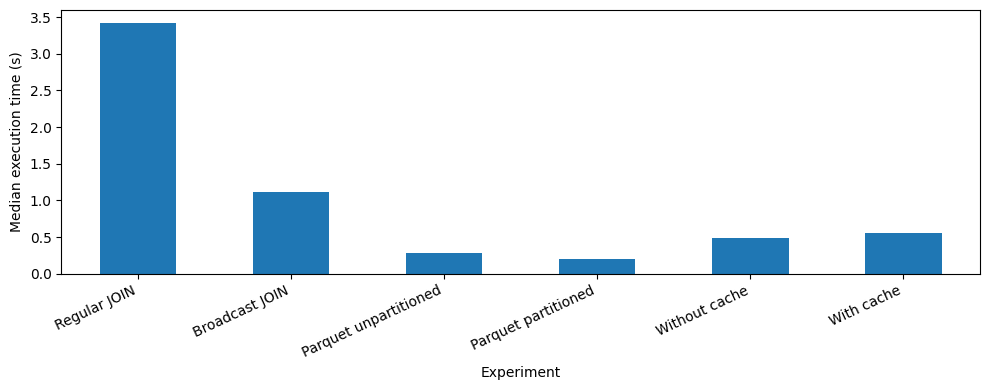

JOIN speedup: 3.081
Partition speedup: 1.364
Cache speedup: 0.867


In [13]:
benchmark_df = pd.DataFrame(benchmarks)
print(benchmark_df.to_string(index=False))

ax = benchmark_df.plot.bar(x="experiment", y="seconds",
                           legend=False, figsize=(10, 4))
ax.set_xlabel("Experiment")
ax.set_ylabel("Median execution time (s)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

print("JOIN speedup:", round(regular_t / broadcast_t, 3))
print("Partition speedup:", round(t_unpart / t_part, 3))
print("Cache speedup:", round(no_cache_t / cache_t, 3))


### Mục 1.1
1. **Vì sao không nên JOIN trực tiếp nhiều bản sao của bảng giao dịch để lấy thông tin sản phẩm hoặc khách hàng?**
   - Tự JOIN (*self-join*) nhiều bản sao của bảng giao dịch lớn (300.000 dòng trở lên) khiến Spark phải đọc lặp lại toàn bộ dữ liệu lớn, nhân bản số cột và phát sinh nhiều bước Shuffle (`Exchange`) tốn kém cả RAM, đĩa tạm và CPU. Tách thành bảng dimension nhỏ (`d_customers`, `d_products`, `d_warehouses`) giúp truy vấn gọn nhẹ hơn, rõ ràng về mô hình dữ liệu và dễ tối ưu (như Broadcast JOIN).
2. **Một cột có giá trị lặp lại nhiều lần có tự động trở thành khóa cho bảng dimension không?**
   - Không. Một cột lặp lại nhiều lần chỉ cho thấy có nhiều giao dịch tham chiếu đến giá trị đó, chưa đủ để làm khóa chuẩn của bảng dimension nếu các thuộc tính mô tả đi kèm (như `customer_city`, `brand`, `warehouse_state`) bị xung đột hoặc thay đổi không nhất quán theo cùng một khóa. Khóa dimension hợp lệ đòi hỏi ánh xạ nhất quán (phụ thuộc hàm từ khóa ra các thuộc tính mô tả).

---

### Mục 1.2
1. **Vì sao không nên so sánh thời gian đọc một file trên Drive với file khác nằm ở `/content`?**
   - Đọc trực tiếp từ `/content/drive` đi qua lớp gắn kết mạng FUSE, phụ thuộc độ trễ mạng và giới hạn băng thông của Google Drive, trong khi `/content` nằm trên ổ đĩa cục bộ của máy ảo Colab. So sánh trực tiếp sẽ trộn lẫn độ trễ I/O mạng/lưu trữ với hiệu năng truy vấn Spark.
2. **`local[2]` có nghĩa là hai máy tính khác nhau cùng chạy Spark hay không?**
   - Không. `local[2]` nghĩa là Spark chạy ở chế độ cục bộ trên một máy ảo duy nhất với 2 worker threads (luồng thực thi) trong cùng một tiến trình JVM, không tạo thêm máy tính hay cụm cluster nhiều máy.

---

### Mục 1.3
1. **Vì sao cần phân biệt số cột gốc và số cột sau khi tạo thuộc tính thời gian?**
   - Phân biệt 25 cột gốc của tệp CSV với các cột phát sinh (`order_year`, `order_month`) giúp kiểm soát chính xác cấu trúc đầu vào, tránh nhầm lẫn khi đối chiếu schema và làm rõ đâu là trường dữ liệu đã có sẵn, đâu là trường được suy diễn phục vụ lọc/phân vùng.
2. **Việc sử dụng `DoubleType` cho tiền tệ có thể gây trở ngại gì khi đối chiếu tổng doanh thu?**
   - `DoubleType` là số thực dấu phẩy động nhị phân (IEEE 754), có thể sinh ra sai số làm tròn thập phân nhỏ khi cộng dồn nhiều giá trị tiền tệ (`sum`). Khi đối chiếu tổng doanh thu yêu cầu độ chính xác đến từng cent, `DecimalType(p, s)` phù hợp hơn vì lưu giá trị thập phân chính xác theo thang đo cố định.

---

### Mục 1.4
1. **Nếu một `product_id` có hai dòng trong bảng sản phẩm, số giao dịch sau JOIN thay đổi thế nào?**
   - Phép JOIN theo `product_id` sẽ biến thành quan hệ một-nhiều/nhiều-nhiều tại các giao dịch có `product_id` trùng lặp đó, làm nhân đôi (tăng thêm) các dòng giao dịch tương ứng trong kết quả JOIN. Nếu tính `SUM(net_amount_usd)` sau đó, doanh thu sẽ bị tính trùng và sai lệch.
2. **Tại sao việc kiểm tra khóa trước khi phân tích doanh thu quan trọng hơn chỉ kiểm tra kết quả ở cuối?**
   - Kiểm tra tính duy nhất và nhất quán khóa (`profiles == keys`) ngay từ khâu chuẩn bị dimension giúp phát hiện sớm lỗi dữ liệu nguồn hoặc lỗi thiết kế khóa trước khi tính toán chỉ số kinh doanh. Nếu chỉ nhìn kết quả cuối cùng, các lỗi nhân bản hoặc mất mát dữ liệu có thể bị che giấu hoặc khó truy nguyên đúng nguyên nhân.

---

### Mục 1.5
1. **Vì sao phép `GROUP BY` có thể phát sinh Shuffle còn `WHERE` trên một cột thường không cần Shuffle?**
   - `WHERE` trên một cột là phép lọc cục bộ theo từng dòng/partition (*Narrow transformation*), mỗi partition tự kiểm tra điều kiện mà không cần trao đổi dữ liệu giữa các partition. Ngược lại, `GROUP BY` cần gom các bản ghi có cùng khóa nhóm về cùng một nơi để tổng hợp chính xác nên thường phát sinh bước `Exchange` (shuffle dữ liệu qua các partition).
2. **Dùng `COUNT(*)` hay `COUNT(DISTINCT customer_id)` để trả lời câu hỏi "bao nhiêu khách hàng đã mua"?**
   - Phải dùng `COUNT(DISTINCT customer_id)`, vì một khách hàng có thể thực hiện nhiều đơn hàng/dòng giao dịch. `COUNT(*)` đếm số dòng giao dịch chứ không đếm số khách hàng duy nhất.

---

### Mục 1.6
1. **Vì sao phải tổng hợp doanh thu của từng sản phẩm trước khi gán `ROW_NUMBER()`?**
   - `ROW_NUMBER()` xếp hạng dựa trên tổng doanh thu của từng sản phẩm trong mỗi `region` (`SUM(o.net_amount_usd)`). Nếu xếp hạng trực tiếp trên bảng giao dịch chưa gom nhóm, mỗi dòng giao dịch lẻ sẽ được tính như một bản ghi riêng biệt thay vì tổng doanh thu theo sản phẩm.
2. **Khi hai sản phẩm cùng doanh thu, quy tắc `ORDER BY` nào giúp kết quả không thay đổi giữa các lần chạy?**
   - Cần bổ sung tiêu chí phá hòa tất định có thứ tự duy nhất hoặc ổn định như `product_id ASC` (`ORDER BY revenue_usd DESC, product_id ASC`). Nếu chỉ sắp xếp theo `revenue_usd DESC`, thứ tự giữa các sản phẩm đồng hạng có thể phụ thuộc vào thứ tự phân vùng/thực thi song song.

---

### Mục 1.7
1. **`Exchange` có bắt buộc xuất hiện ở mọi truy vấn Spark SQL không?**
   - Không. Những truy vấn chỉ đọc, lọc (`Filter`), chiếu cột (`Project`) hoặc giới hạn số dòng cục bộ/giới hạn (`Limit`) mà không yêu cầu phân phối lại dữ liệu theo khóa (như `GROUP BY`, `JOIN` không broadcast, `repartition`, `ORDER BY` toàn cục) có thể thực thi mà không cần `Exchange`.
2. **Vì sao không thể chỉ đếm số dòng mã SQL để dự đoán truy vấn nào chậm hơn?**
   - Độ dài câu lệnh SQL không phản ánh khối lượng dữ liệu đọc, số phép JOIN, mức độ Shuffle, số lần quét dữ liệu hay độ phức tạp tính toán bên trong từng toán tử. Một truy vấn ngắn gọn có JOIN nhiều bảng và `GROUP BY` trên dữ liệu lớn có thể chậm hơn nhiều so với truy vấn dài hơn nhưng chỉ lọc đơn giản.

---

### Mục 1.8
1. **Khi nào Broadcast JOIN có nguy cơ phản tác dụng?**
   - Khi bảng được chọn broadcast thực chất không nhỏ hoặc phình lớn vượt ngưỡng bộ nhớ của Executor/Driver, gây tốn bộ nhớ, tăng áp lực Garbage Collection, làm chậm quá trình tuần tự hóa/phát quảng bá dữ liệu hoặc gây lỗi `OutOfMemoryError`. Trên tập dữ liệu nhỏ, chênh lệch thời gian shuffle đôi khi rất nhỏ so với chi phí chuẩn bị và truyền broadcast.
2. **Vì sao cần tắt AQE và tự động broadcast khi mục tiêu là quan sát khác biệt rõ giữa hai chiến lược?**
   - Adaptive Query Execution (AQE) và `autoBroadcastJoinThreshold` có thể tự động đổi chiến lược JOIN trong lúc chạy (ví dụ tự chuyển sang Broadcast Hash Join khi thấy bảng nhỏ). Tắt chúng giúp kiểm soát chặt chẽ từng phép thử để quan sát đúng sự khác biệt giữa kế hoạch Regular JOIN và Broadcast JOIN.

---

### Mục 1.9
1. **Tại sao lọc theo `order_year` và `order_month` có lợi cho dữ liệu partitioned nhưng lọc theo `product_id` có thể không tận dụng được phân vùng này?**
   - Dữ liệu được ghi theo thư mục phân vùng `order_year=.../order_month=...`, nên điều kiện `WHERE order_year = 2025 AND order_month = 3` cho phép Spark bỏ qua các thư mục tháng/năm khác ngay khi quét (*Partition Pruning*). Ngược lại, `product_id` không phải cột phân vùng nên Spark vẫn phải duyệt qua các thư mục partition liên quan để đọc dữ liệu.
2. **Vì sao quá nhiều partition nhỏ có thể làm hiệu năng giảm?**
   - Quá nhiều partition (hoặc quá nhiều thư mục/tệp nhỏ) làm tăng chi phí quản lý metadata, tăng số lượng task cần lập lịch, giảm hiệu quả đọc tuần tự/gộp khối I/O và gây phân mảnh dữ liệu.

---

### Mục 1.10
1. **Trong phép đo này, thời gian materialize cache đã được tính vào "With cache" chưa? Nếu chưa, kết luận cần giới hạn như thế nào?**
   - Chưa. Lệnh materialize (`spark.table("f_orders").count()`) chạy trước khi gọi `benchmark_sql(QUERY_REUSE)`. Do đó, `cache_t` chỉ phản ánh tốc độ của các truy vấn tiếp theo khi dữ liệu đã nằm sẵn trong cache, chưa cộng chi phí lần đầu nạp và nén/lưu dữ liệu vào bộ nhớ; kết luận cần ghi rõ giới hạn này.
2. **Trường hợp truy vấn chỉ chạy một lần có nhất thiết nên cache không?**
   - Không nhất thiết (thường không nên). Nếu bảng chỉ được truy vấn một lần duy nhất, việc cache thêm chi phí materialize và chiếm dụng bộ nhớ của các tác vụ khác mà không có lượt đọc lại nào để bù đắp chi phí đó.

---

### Mục 1.11
1. **Nếu một kỹ thuật làm tăng thời gian xử lý, có nên coi đó là sai chương trình không?**
   - Không nhất thiết là sai chương trình, miễn là kết quả trả về vẫn đúng và không có lỗi runtime. Trong benchmark thực tế, một kỹ thuật tối ưu có thể làm tăng thời gian do kích thước dữ liệu nhỏ, chi phí overhead lớn hơn lợi ích, hoặc cấu hình máy ảo chưa phù hợp — cần phân tích trung thực nguyên nhân thay vì sửa số liệu.
2. **Kết quả đo trên 300.000 dòng có đủ để khẳng định hiệu năng với hàng trăm triệu dòng không?**
   - Không đủ. Ở quy mô 300.000 dòng, nhiều chi phí cố định (khởi tạo tác vụ, đọc file nhỏ, bộ nhớ đệm) chiếm tỷ trọng khác với dữ liệu hàng trăm triệu dòng — nơi áp lực bộ nhớ, shuffle quy mô lớn, skew dữ liệu, GC và I/O mạng/lưu trữ thể hiện rõ rệt hơn nhiều.
3. **Ba kỹ thuật tối ưu đã quan sát khác nhau về cơ chế giảm chi phí như thế nào?**
   - **Broadcast JOIN:** Giảm chi phí trao đổi/shuffle dữ liệu của bảng lớn bằng cách gửi bản sao bảng nhỏ tới các phân vùng xử lý.
   - **Partition Pruning (với Parquet):** Giảm chi phí đọc I/O từ đĩa bằng cách loại bỏ sớm các phân vùng thư mục không thỏa mãn điều kiện lọc và tận dụng định dạng cột Parquet.
   - **Cache:** Giảm chi phí tính toán và đọc lại dữ liệu lặp lại từ nguồn lưu trữ bằng cách giữ dữ liệu trung gian/bảng trong bộ nhớ cho các lượt truy vấn sau.